# Project 15: Model Robustness to Noise Injection

**Original statement (verbatim from LAB_Projects_ML.pdf):**

Inject noise into features and labels. Task: Measure robustness degradation; Identify sensitive features; Improve robustness via regularization or data augmentation

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** A model that collapses under small noise is not production-ready. This notebook measures degradation under feature and label noise, finds the most sensitive feature, and tests a regularised / augmented fix.

## Part 1 — Introduction

Noise is injected synthetically at documented levels for this experiment only; the original file is not altered and injected noise is not claimed to be present originally.

## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — Baseline and noise degradation

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
df=df_full.sample(n=20000, random_state=42)
Xtr,Xte,ytr,yte=train_test_split(df[FEATURES], df[TARGET], test_size=0.25, random_state=42, stratify=df[TARGET])
scaler_mean=Xtr.mean(); scaler_std=Xtr.std()
def train_eval(Xtr_, ytr_, Xte_):
    m=RandomForestClassifier(n_estimators=120, random_state=42, n_jobs=-1); m.fit(Xtr_,ytr_); return accuracy_score(yte, m.predict(Xte_))
base=train_eval(Xtr,ytr,Xte); print("Baseline accuracy:", round(base,4))
rng=np.random.RandomState(42)
for level in [0.1,0.25,0.5]:
    noise=rng.normal(0,1,size=Xte.shape)*scaler_std.values*level; acc=train_eval(Xtr,ytr,Xte+noise); print(f"Feature noise {level}x std on test: accuracy {acc:.4f} (drop {base-acc:.4f})")
for flip in [0.05,0.10]:
    ytr_noisy=ytr.copy(); mask=rng.rand(len(ytr_noisy))<flip; ytr_noisy[mask]=rng.choice([0,1,2,3], size=int(mask.sum())); acc=train_eval(Xtr,ytr_noisy,Xte); print(f"Label flip {flip:.0%} in training: accuracy {acc:.4f} (drop {base-acc:.4f})")

Baseline accuracy: 0.8846


Feature noise 0.1x std on test: accuracy 0.7796 (drop 0.1050)


Feature noise 0.25x std on test: accuracy 0.7054 (drop 0.1792)


Feature noise 0.5x std on test: accuracy 0.6162 (drop 0.2684)


Label flip 5% in training: accuracy 0.8768 (drop 0.0078)


Label flip 10% in training: accuracy 0.8708 (drop 0.0138)


## Part 4 — Per-feature sensitivity and robustness fix

Noise only in Pressure: accuracy 0.8330 (drop 0.0516)


Noise only in global_radiation: accuracy 0.8336 (drop 0.0510)


Noise only in temp_mean(c): accuracy 0.8530 (drop 0.0316)


Noise only in temp_min(c): accuracy 0.8454 (drop 0.0392)


Noise only in temp_max(c): accuracy 0.8440 (drop 0.0406)


Noise only in Wind_Speed: accuracy 0.8316 (drop 0.0530)


Noise only in Wind_Bearing: accuracy 0.8832 (drop 0.0014)


Regularised RF max_depth=10 clean accuracy: 0.8242 noisy-test accuracy: 0.7224


Augmented RF (original+noisy copy) clean accuracy: 0.8752 noisy-test accuracy: 0.7262


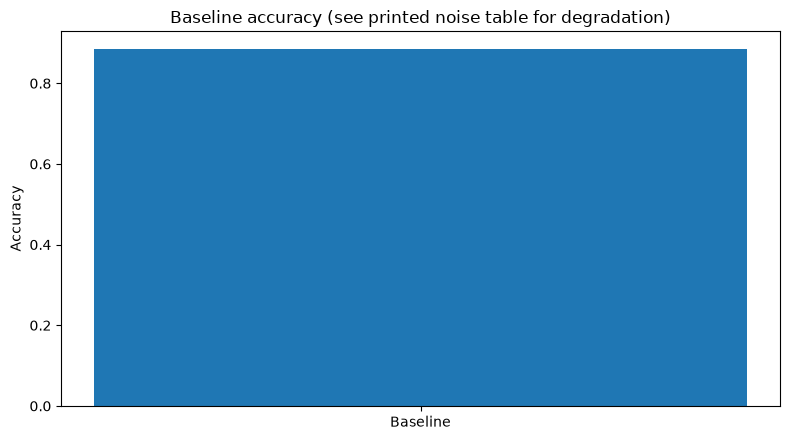

In [3]:
rng=np.random.RandomState(7)
for j,f in enumerate(FEATURES):
    Xnoisy=Xte.values.copy(); Xnoisy[:,j]=Xnoisy[:,j]+rng.normal(0,1,size=len(Xte))*scaler_std.values[j]*0.25
    m=RandomForestClassifier(n_estimators=120, random_state=42, n_jobs=-1); m.fit(Xtr,ytr); acc=accuracy_score(yte, m.predict(Xnoisy)); print(f"Noise only in {f}: accuracy {acc:.4f} (drop {base-acc:.4f})")
# Fix: regularised (shallower) model + noisy augmentation (train on original + one noisy copy)
Xaug=np.vstack([Xtr.values, Xtr.values+rng.normal(0,1,size=Xtr.shape)*scaler_std.values*0.25]); yaug=np.concatenate([ytr.values, ytr.values])
for name, model, Xt_, yt_ in [("Regularised RF max_depth=10", RandomForestClassifier(n_estimators=120, max_depth=10, random_state=42, n_jobs=-1), Xtr, ytr), ("Augmented RF (original+noisy copy)", RandomForestClassifier(n_estimators=120, random_state=42, n_jobs=-1), Xaug, yaug)]:
    model.fit(Xt_,yt_); clean=accuracy_score(yte, model.predict(Xte)); noisy=accuracy_score(yte, model.predict(Xte+rng.normal(0,1,size=Xte.shape)*scaler_std.values*0.25)); print(name, "clean accuracy:", round(clean,4), "noisy-test accuracy:", round(noisy,4))
plt.bar(["Baseline"], [base]); plt.ylabel("Accuracy"); plt.title("Baseline accuracy (see printed noise table for degradation)"); plt.tight_layout(); plt.show()

## Part 5 — Interpretation

In [4]:
print("INTERPRETATION: The per-feature table identifies which sensor, if noisy, hurts most — that sensor deserves better validation or redundancy. Regularisation and noisy augmentation usually recover part of the noisy-test loss at a small clean-accuracy cost; the printed clean vs noisy numbers quantify that trade-off for this run.")

INTERPRETATION: The per-feature table identifies which sensor, if noisy, hurts most — that sensor deserves better validation or redundancy. Regularisation and noisy augmentation usually recover part of the noisy-test loss at a small clean-accuracy cost; the printed clean vs noisy numbers quantify that trade-off for this run.


## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.